# FEVS 2024 – Step 4: What drives engagement, and who plans to leave?

**Business questions**
1. Which workplace factors are most linked to **engagement**?
2. Which factors are most linked to people **planning to leave**?
3. Which factors are **important but scoring low** – where should HR act first?

**Method (kept simple and explainable)**
- **Candidate drivers:** the 52 survey questions that are *not* part of the outcome indices
  (Engagement, Global Satisfaction, Employee Experience) – so we never test engagement against itself.
- **Importance:** weighted correlation between each driver and a person's engagement score.
- **Check:** a multiple regression on the top drivers, to see which still matter when compared together.
- **Leaving:** how much more often people who answer negatively plan to leave than people who answer positively.
- **Priority matrix:** importance (how strongly linked) vs performance (% positive today).

*Correlation shows a link, not proof of cause. Findings are written as "linked to", never "causes".*

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

CLEAN = Path("../data/clean")
OUT = Path("../outputs")
OUT.mkdir(exist_ok=True)

df = pd.read_csv(CLEAN / "fevs_2024_clean.csv.gz", low_memory=False)
scores = pd.read_csv(CLEAN / "fevs_2024_person_scores.csv.gz",
                     usecols=["RandomID", "eei_score", "wellbeing_score", "plans_to_leave"])
df = df.drop(columns=["plans_to_leave"]).merge(scores, on="RandomID", how="left")
print(f"{len(df):,} respondents | with engagement score: {df['eei_score'].notna().sum():,} "
      f"| answered the leaving question: {df['plans_to_leave'].notna().sum():,}")

674,207 respondents | with engagement score: 659,562 | answered the leaving question: 632,298


## 1. The candidate drivers

Each question gets a short label and a **theme**, so results are easy to read on a dashboard.

In [2]:
DRIVERS = {  # question: (short label, theme)
    "Q1":  ("Chance to improve my skills",            "Development"),
    "Q5":  ("Reasonable workload",                    "Well-being"),
    "Q8":  ("Can report wrongdoing without fear",     "Fairness"),
    "Q9":  ("Enough information to do my job",        "Resources"),
    "Q10": ("Training I need",                        "Development"),
    "Q11": ("Held accountable for quality",           "Performance management"),
    "Q12": ("Know how well I'm doing",                "Performance management"),
    "Q13": ("Autonomy in how I work",                 "Autonomy"),
    "Q14": ("Decide without asking permission",       "Autonomy"),
    "Q15": ("Co-workers cooperate",                   "Teamwork"),
    "Q17": ("Performance differences recognised",     "Recognition"),
    "Q18": ("Team shares job knowledge",              "Teamwork"),
    "Q19": ("Team has the skills needed",             "Teamwork"),
    "Q20": ("Team meets customer needs",              "Team performance"),
    "Q21": ("Team contributes to agency",             "Team performance"),
    "Q22": ("Team produces high-quality work",        "Team performance"),
    "Q23": ("Team adapts to new priorities",          "Team performance"),
    "Q24": ("New hires have the right skills",        "Teamwork"),
    "Q25": ("Can influence decisions in my unit",     "Involvement"),
    "Q26": ("Know my work unit's goals",              "Clarity"),
    "Q27": ("Resources to develop new ideas",         "Innovation"),
    "Q28": ("Unit manages disruptions well",          "Agility"),
    "Q29": ("Team looks for better ways to work",     "Innovation"),
    "Q30": ("Team uses new ideas",                    "Innovation"),
    "Q31": ("Team sees change as opportunity",        "Agility"),
    "Q32": ("Customer needs a top priority",          "Customer focus"),
    "Q33": ("Team improves customer service",         "Customer focus"),
    "Q34": ("Team supports my work-life balance",     "Well-being"),
    "Q35": ("Recognised for high-quality work",       "Recognition"),
    "Q36": ("Protected from health and safety risks", "Well-being"),
    "Q37": ("Organisation achieves its mission",      "Organisation"),
    "Q38": ("Understand organisation's priorities",   "Clarity"),
    "Q39": ("Survey results are shared",              "Communication"),
    "Q40": ("Information shared openly",              "Communication"),
    "Q41": ("Approval process allows timely work",    "Process"),
    "Q42": ("Organisation adapts to new priorities",  "Agility"),
    "Q43": ("Prepared for physical security threats", "Security"),
    "Q44": ("Prepared for cyber threats",             "Security"),
    "Q45": ("No favouritism or political pressure",   "Fairness"),
    "Q47": ("Survey results will be used",            "Communication"),
    "Q49": ("Supervisor supports work-life balance",  "Well-being"),
    "Q53": ("Supervisor holds me accountable",        "Performance management"),
    "Q55": ("Supervisor gives useful suggestions",    "Performance management"),
    "Q56": ("Feedback throughout the year",           "Performance management"),
    "Q60": ("Managers connect work units",            "Communication"),
    "Q63": ("Leaders support work-life programmes",   "Well-being"),
    "Q64": ("Management encourages innovation",       "Innovation"),
    "Q65": ("Management makes effective changes",     "Change management"),
    "Q66": ("Management involves employees",          "Involvement"),
    "Q67": ("Satisfied with my involvement",          "Involvement"),
    "Q68": ("Satisfied with info from management",    "Communication"),
    "Q69": ("Satisfied with my recognition",          "Recognition"),
}
drivers = list(DRIVERS)
print(f"{len(drivers)} candidate drivers across {len(set(t for _, t in DRIVERS.values()))} themes")

52 candidate drivers across 19 themes


## 2. Helper functions (weighted, ignoring blanks)

In [3]:
def wcorr(x, y, w):
    """Weighted Pearson correlation, using only rows where both x and y are answered."""
    m = x.notna() & y.notna()
    x, y, w = x[m], y[m], w[m]
    mx, my = np.average(x, weights=w), np.average(y, weights=w)
    cov = np.average((x - mx) * (y - my), weights=w)
    return cov / np.sqrt(np.average((x - mx) ** 2, weights=w) * np.average((y - my) ** 2, weights=w))

def wpct(cond, w, valid):
    """Weighted % of rows meeting `cond` among `valid` rows."""
    return 100 * (w[valid & cond]).sum() / w[valid].sum()

## 3. Importance and performance of every driver

- **Importance** = correlation with the engagement score (0 = no link, 1 = perfect link)
- **Performance** = weighted % positive today

In [4]:
w = df["POSTWT"]
rows = []
for q in drivers:
    answered = df[q].notna()
    rows.append({
        "question": q,
        "driver": DRIVERS[q][0],
        "theme": DRIVERS[q][1],
        "importance_r": wcorr(df[q], df["eei_score"], w),
        "pct_positive": wpct(df[q] >= 4, w, answered),
        "answered": int(answered.sum()),
    })
res = pd.DataFrame(rows).sort_values("importance_r", ascending=False).reset_index(drop=True)
res.index += 1
res[["question", "driver", "theme", "importance_r", "pct_positive"]].round(2).head(15)

,question,driver,theme,importance_r,pct_positive
1,Q64,Management encourages innovation,Innovation,0.77,60.16
2,Q60,Managers connect work units,Communication,0.77,61.27
3,Q65,Management makes effective changes,Change management,0.77,55.42
4,Q68,Satisfied with info from management,Communication,0.76,56.47
5,Q67,Satisfied with my involvement,Involvement,0.76,54.32
6,Q1,Chance to improve my skills,Development,0.75,72.23
7,Q66,Management involves employees,Involvement,0.74,47.79
8,Q69,Satisfied with my recognition,Recognition,0.73,57.42
9,Q55,Supervisor gives useful suggestions,Performance management,0.73,73.32
10,Q45,No favouritism or political pressure,Fairness,0.72,55.99


## 4. Check: do the top drivers still matter when compared together?

Many drivers overlap (people who like their manager often like many things).
A **multiple regression** on the top 12 drivers shows each one's own contribution when the others are held
equal. Answers are standardised so the coefficients can be compared (bigger = more important).
Only people who answered all 12 are used.

In [5]:
top12 = res["question"].head(12).tolist()
d = df[top12 + ["eei_score", "POSTWT"]].dropna()
X = (d[top12] - d[top12].mean()) / d[top12].std()
y = (d["eei_score"] - d["eei_score"].mean()) / d["eei_score"].std()
sw = np.sqrt(d["POSTWT"] / d["POSTWT"].mean())
Xw = np.column_stack([np.ones(len(X)), X.values]) * sw.values[:, None]
beta, *_ = np.linalg.lstsq(Xw, y.values * sw.values, rcond=None)

pred = np.column_stack([np.ones(len(X)), X.values]) @ beta
r2 = 1 - np.average((y - pred) ** 2, weights=d["POSTWT"]) / np.average((y - y.mean()) ** 2, weights=d["POSTWT"])

reg = (pd.DataFrame({"question": top12, "std_beta": beta[1:]})
       .assign(driver=lambda t: t["question"].map(lambda q: DRIVERS[q][0]))
       .sort_values("std_beta", ascending=False).round(3))
print(f"Based on {len(d):,} people. Together these 12 explain {100 * r2:.0f}% of the differences in engagement (R²).")
reg

Based on 534,292 people. Together these 12 explain 89% of the differences in engagement (R²).


,question,std_beta,driver
8,Q55,0.277,Supervisor gives useful suggestions
5,Q1,0.217,Chance to improve my skills
1,Q60,0.149,Managers connect work units
10,Q63,0.104,Leaders support work-life programmes
9,Q45,0.094,No favouritism or political pressure
4,Q67,0.093,Satisfied with my involvement
0,Q64,0.090,Management encourages innovation
2,Q65,0.068,Management makes effective changes
3,Q68,0.046,Satisfied with info from management
11,Q35,0.045,Recognised for high-quality work


## 5. Who plans to leave?

Overall leaving intention first, then for each driver: the % planning to leave among people who answered
**negatively (1–2)** vs **positively (4–5)**. A big gap means the factor is closely linked to leaving.

In [6]:
valid_leave = df["plans_to_leave"].notna()
overall_leave = wpct(df["plans_to_leave"] == 1, w, valid_leave)
print(f"Overall: {overall_leave:.1f}% are considering leaving within a year")

reasons = (df.loc[valid_leave].groupby("DLEAVING")["POSTWT"].sum() / w[valid_leave].sum() * 100).round(1)
display(reasons.sort_values(ascending=False).rename("% of respondents").to_frame())

leave = []
for q in drivers:
    neg = valid_leave & df[q].isin([1, 2])
    pos = valid_leave & df[q].isin([4, 5])
    leave.append({
        "question": q,
        "leave_if_negative": wpct(df["plans_to_leave"] == 1, w, neg),
        "leave_if_positive": wpct(df["plans_to_leave"] == 1, w, pos),
        "leave_r": wcorr(df[q], df["plans_to_leave"], w),
    })
leave = pd.DataFrame(leave)
leave["leave_gap_pts"] = leave["leave_if_negative"] - leave["leave_if_positive"]
res = res.merge(leave, on="question")

(res.sort_values("leave_gap_pts", ascending=False)
    [["question", "driver", "leave_if_negative", "leave_if_positive", "leave_gap_pts"]]
    .round(1).head(10))

Overall: 36.8% are considering leaving within a year


,% of respondents
DLEAVING,
No,63.2
"Yes, to take another job within the Federal Government",20.3
"Yes, other",12.4
"Yes, to take another job outside the Federal Government",4.1


,question,driver,leave_if_negative,leave_if_positive,leave_gap_pts
5,Q1,Chance to improve my skills,68.8,28.4,40.5
4,Q67,Satisfied with my involvement,63.6,24.0,39.6
50,Q20,Team meets customer needs,72.6,33.6,39.0
12,Q49,Supervisor supports work-life balance,70.8,32.5,38.3
41,Q21,Team contributes to agency,70.9,32.9,38.1
20,Q26,Know my work unit's goals,70.4,32.6,37.9
10,Q63,Leaders support work-life programmes,64.7,26.9,37.8
7,Q69,Satisfied with my recognition,62.5,24.8,37.7
48,Q22,Team produces high-quality work,70.3,32.6,37.7
3,Q68,Satisfied with info from management,62.0,24.9,37.1


## 6. Priority matrix: important but scoring low

Split at the median of each axis:

| | Low performance | High performance |
|---|---|---|
| **High importance** | **Fix first** | Protect |
| **Low importance** | Monitor | Maintain |

In [7]:
imp_cut, perf_cut = res["importance_r"].median(), res["pct_positive"].median()
res["priority"] = np.select(
    [(res["importance_r"] >= imp_cut) & (res["pct_positive"] < perf_cut),
     (res["importance_r"] >= imp_cut) & (res["pct_positive"] >= perf_cut),
     (res["importance_r"] < imp_cut) & (res["pct_positive"] < perf_cut)],
    ["Fix first", "Protect", "Monitor"], default="Maintain")

print(f"Cut-offs: importance r = {imp_cut:.2f}, performance = {perf_cut:.1f}% positive\n")
fix_first = res[res["priority"] == "Fix first"].sort_values("importance_r", ascending=False)
fix_first[["question", "driver", "theme", "importance_r", "pct_positive", "leave_gap_pts"]].round(2)

Cut-offs: importance r = 0.65, performance = 71.0% positive



,question,driver,theme,importance_r,pct_positive,leave_gap_pts
0,Q64,Management encourages innovation,Innovation,0.77,60.16,36.58
1,Q60,Managers connect work units,Communication,0.77,61.27,33.68
2,Q65,Management makes effective changes,Change management,0.77,55.42,37.08
3,Q68,Satisfied with info from management,Communication,0.76,56.47,37.14
4,Q67,Satisfied with my involvement,Involvement,0.76,54.32,39.56
6,Q66,Management involves employees,Involvement,0.74,47.79,33.71
7,Q69,Satisfied with my recognition,Recognition,0.73,57.42,37.70
9,Q45,No favouritism or political pressure,Fairness,0.72,55.99,35.35
10,Q63,Leaders support work-life programmes,Well-being,0.71,62.93,37.81
11,Q35,Recognised for high-quality work,Recognition,0.70,62.48,34.00


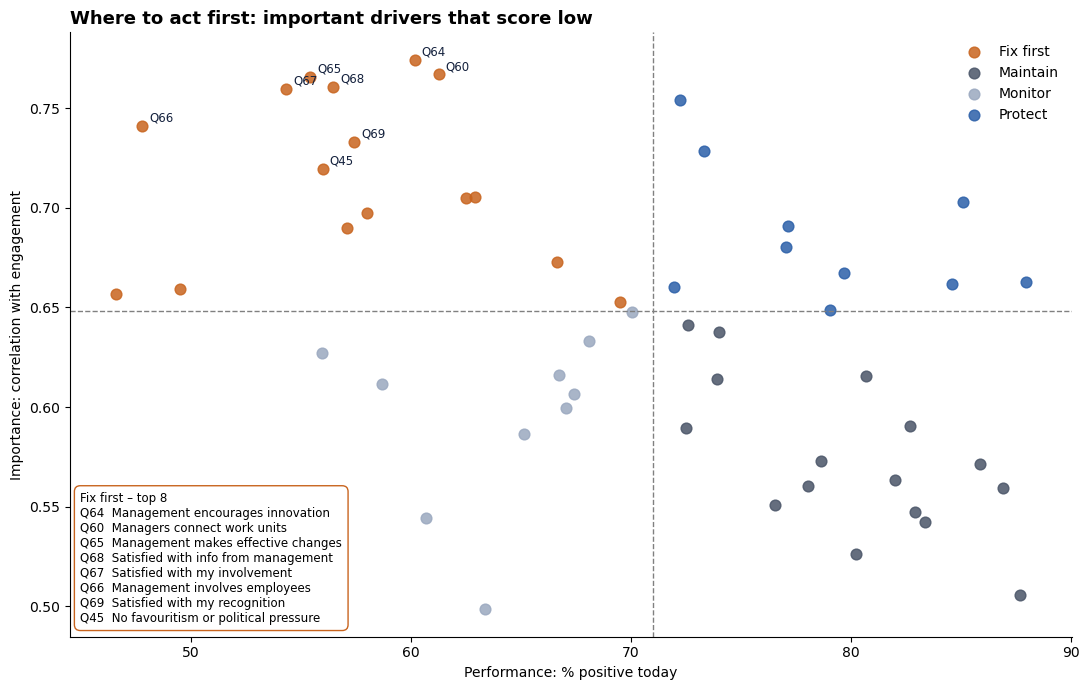

In [8]:
colors = {"Fix first": "#C8641E", "Protect": "#2B5FA8", "Monitor": "#9AA8BF", "Maintain": "#4A5568"}
fig, ax = plt.subplots(figsize=(11, 7))
for p, g in res.groupby("priority"):
    ax.scatter(g["pct_positive"], g["importance_r"], s=60, color=colors[p], label=p, alpha=0.85)
ax.axvline(perf_cut, color="grey", ls="--", lw=1)
ax.axhline(imp_cut, color="grey", ls="--", lw=1)
top_fix = fix_first.head(8)
for _, r in top_fix.iterrows():      # short codes on the dots, full names in a key (labels would overlap)
    ax.annotate(r["question"], (r["pct_positive"], r["importance_r"]),
                xytext=(5, 3), textcoords="offset points", fontsize=8.5, color="#14213D")
key = "Fix first – top 8\n" + "\n".join(f"{r.question}  {r.driver}" for r in top_fix.itertuples())
ax.text(0.01, 0.02, key, transform=ax.transAxes, fontsize=8.5, va="bottom",
        bbox=dict(boxstyle="round,pad=0.5", fc="white", ec="#C8641E"))
ax.set_xlabel("Performance: % positive today")
ax.set_ylabel("Importance: correlation with engagement")
ax.set_title("Where to act first: important drivers that score low", loc="left", fontsize=13, weight="bold")
ax.legend(frameon=False, loc="upper right")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig(OUT / "priority_matrix.png", dpi=200)
plt.show()

## 7. Themes: which areas matter most overall?

In [9]:
themes = (res.groupby("theme")
             .agg(drivers=("question", "count"),
                  avg_importance=("importance_r", "mean"),
                  avg_pct_positive=("pct_positive", "mean"),
                  avg_leave_gap=("leave_gap_pts", "mean"))
             .sort_values("avg_importance", ascending=False).round(2))
themes

,drivers,avg_importance,avg_pct_positive,avg_leave_gap
theme,,,,
Change management,1,0.77,55.42,37.08
Involvement,3,0.72,57.39,35.57
Recognition,3,0.70,55.49,34.43
Communication,5,0.69,59.55,34.38
Fairness,2,0.69,63.97,35.12
Development,2,0.69,69.47,36.01
Innovation,4,0.68,63.18,33.63
Organisation,1,0.67,79.68,36.59
Performance management,5,0.66,80.47,34.52


## 8. Save the results for the dashboard and the write-up

In [10]:
res.round(3).to_csv(CLEAN / "driver_analysis.csv", index=False)
reg.to_csv(CLEAN / "driver_regression_top12.csv", index=False)
themes.to_csv(CLEAN / "driver_themes.csv")
for f in ["driver_analysis.csv", "driver_regression_top12.csv", "driver_themes.csv"]:
    print("Saved", CLEAN / f)
print("Saved", OUT / "priority_matrix.png")

Saved ..\data\clean\driver_analysis.csv
Saved ..\data\clean\driver_regression_top12.csv
Saved ..\data\clean\driver_themes.csv
Saved ..\outputs\priority_matrix.png


## Summary

- Ranked 52 workplace factors by how strongly they are linked to engagement
- Checked the top 12 together with a regression
- Measured how each factor relates to people planning to leave
- Built a priority matrix: the **Fix first** list is where HR should act

**Next step (Step 5):** the Power BI dashboard (overview, drivers, agencies, well-being), then the write-up
with three recommendations.